# Calibrating radars from the weather: ZDR from snow, Z from self-consistency

**Why.** Every rain estimate so far assumed the radars' Z and ZDR were right. A 1 dB Z error is ~15 % in rain
(Marshall-Palmer); Ryzhkov et al. (2005, JTECH, doi:10.1175/JTECH1772.1) ask for Z within 1 dB and ZDR within
0.2 dB. Engineering calibration records are rarely public, but the weather offers targets with known properties:

- **ZDR offset** from dry snow just above the melting layer on steep sweeps (intrinsic ZDR ~0.2 dB x cos^2 elev),
  with light rain as a cross-check;
- **Z offset** from self-consistency (S band only): in rain Z, ZDR and KDP are linked, and KDP needs no calibration.

Four radars from the earlier notebooks: KTLX and KDAX (NEXRAD, S band), Anjalankoski (FMI, C band; its neighbours
put it 1-2.4 dB below them, radarwow-mosaic notebook 01) and Tablazo (IDEAM, C band; the health check flagged a
ZDR of -2.6 dB in light rain, radarwow-verify notebook 07).

In [1]:
# Colab: uncomment to install
!pip install -q cfgrib eccodes "git+https://github.com/manmeet3591/radarwow-pipeline" "git+https://github.com/manmeet3591/radarwow-calibration"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.attenuation import Testud2000ZPHI
from radarwow.calibration import RELATIONS, rain_bins, self_consistency_z_bias, zdr_offset_light_rain, zdr_offset_snow
from radarwow.classification import MeltingLayerTracker, melting_layer_from_volume
from radarwow.core import fmi_aws_files, ideam_aws_files, nexrad_aws_files, open_volume
from radarwow.estimation import unique_tilts
from radarwow.kdp import Vulpiani2012KDP
from radarwow.verify import hrrr_freezing_level, pressure_level_freezing_level

CACHE = os.path.expanduser("~/.cache/radarwow")
FIG = "../docs/figures"
CASES = {"KTLX": ("nexrad", "S", "2022-05-05 07:00", "2022-05-05 11:00"),
         "KDAX": ("nexrad", "S", "2021-10-24 12:00", "2021-10-24 16:00"),
         "fianj": ("fmi", "C", "2023-08-30 12:00", "2023-08-30 16:00"),
         "Tablazo": ("ideam", "C", "2023-08-20 00:00", "2023-08-20 12:00")}
FIND = {"nexrad": nexrad_aws_files, "fmi": fmi_aws_files, "ideam": ideam_aws_files}

## 1. Collect rain and snow gates (one volume every ~15 minutes)

In [3]:
pooled = {}
for site, (src, band, s, e) in CASES.items():
    files = FIND[src](site, s, e, cache_dir=f"{CACHE}/{src}")
    step = max(1, len(files) // 16)
    tracker, low, high, mls = MeltingLayerTracker(), [], [], []
    for t, f in files[::step]:
        try:
            dt = open_volume(f, band=band)
        except Exception:  # noqa: BLE001
            continue
        lat0, lon0, alt = (float(dt[k].values) for k in ("latitude", "longitude", "altitude"))
        fzf = hrrr_freezing_level if src == "nexrad" else pressure_level_freezing_level
        sub = "hrrr" if src == "nexrad" else "openmeteo"
        fz = (fzf(pd.Timestamp(t).floor("h"), lat0, lon0, f"{CACHE}/{sub}") - alt) / 1e3
        ml, _ = melting_layer_from_volume(dt)
        use, _ = tracker.update(t, ml, prior_top_km=fz)
        bottom, top = (use.bottom_km, use.top_km) if use else (fz - 0.5, fz)
        mls.append((bottom, top))
        tilts = unique_tilts(dt)
        el, name = tilts[0]
        ds = dt[name].to_dataset()
        ds = ds.isel(range=ds["range"].values <= 150e3)
        if "PHIDP" in ds:
            ds = Testud2000ZPHI()(Vulpiani2012KDP()(ds, band=band), band=band)
        low.append((ds, bottom))
        high += [(dt[n].to_dataset(), top) for el_, n in tilts if el_ >= 10]
    pooled[site] = dict(low=low, high=high, band=band, ml=np.nanmedian(np.array(mls), axis=0))
display(Markdown("\n".join(f"- {k}: {len(v['low'])} volumes, melting layer {v['ml'][0]:.1f}-{v['ml'][1]:.1f} km above the radar, "
                           f"{len(v['high'])} sweeps at >= 10 deg" for k, v in pooled.items())))

- KTLX: 18 volumes, melting layer 2.6-3.3 km above the radar, 90 sweeps at >= 10 deg
- KDAX: 20 volumes, melting layer 3.3-3.8 km above the radar, 81 sweeps at >= 10 deg
- fianj: 16 volumes, melting layer 2.4-3.3 km above the radar, 64 sweeps at >= 10 deg
- Tablazo: 16 volumes, melting layer 1.1-1.6 km above the radar, 36 sweeps at >= 10 deg

## 2. ZDR offsets

In [4]:
rows = []
for site, p in pooled.items():
    snow, ns = zdr_offset_snow([d for d, _ in p["high"]], ml_top_km=p["ml"][1])
    rain, nr = zdr_offset_light_rain([d for d, _ in p["low"]], ml_bottom_km=p["ml"][0])
    p["zdr_offset"] = snow if np.isfinite(snow) else rain
    rows.append(dict(radar=site, band=p["band"], snow_offset_dB=snow, snow_gates=ns, light_rain_offset_dB=rain, rain_gates=nr))
zt = pd.DataFrame(rows).round(2)
display(Markdown("**ZDR offset** (measured minus expected; snow: 0.2 dB x cos^2 elevation, light rain: 0.25 dB)\n\n" + zt.to_markdown(index=False)))

**ZDR offset** (measured minus expected; snow: 0.2 dB x cos^2 elevation, light rain: 0.25 dB)

| radar   | band   |   snow_offset_dB |   snow_gates |   light_rain_offset_dB |   rain_gates |
|:--------|:-------|-----------------:|-------------:|-----------------------:|-------------:|
| KTLX    | S      |             0.01 |       371245 |                   0.38 |       815055 |
| KDAX    | S      |             0.23 |       233734 |                   0.17 |      1955845 |
| fianj   | C      |             0.09 |        65460 |                   0.21 |       490197 |
| Tablazo | C      |           nan    |            4 |                  -2.79 |        24961 |

## 3. Z offset from self-consistency (S band)

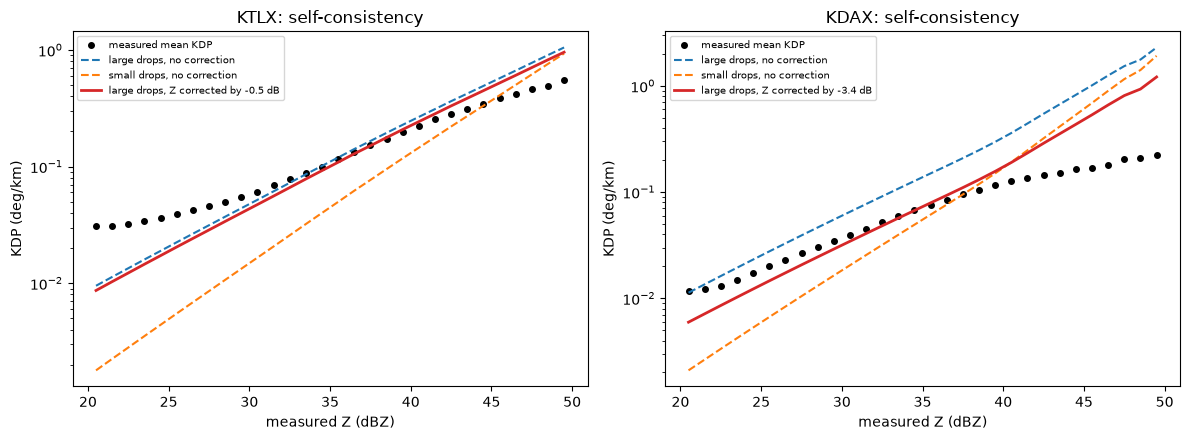

**Z bias** (measured minus true; accepted if the misfit < 0.07, Ryzhkov et al. 2005)

| radar   |   Z_bias_dB | relation    |   misfit | accepted   |   gates |
|:--------|------------:|:------------|---------:|:-----------|--------:|
| KTLX    |        0.49 | large drops |     0.07 | True       | 2189802 |
| KDAX    |        3.39 | large drops |     0.04 | True       | 5216556 |

In [5]:
zrows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, site in zip(axes, ["KTLX", "KDAX"]):
    p = pooled[site]
    bins = rain_bins([d for d, _ in p["low"]], ml_bottom_km=p["ml"][0], zdr_offset_db=p["zdr_offset"])
    r = self_consistency_z_bias(bins)
    zrows.append(dict(radar=site, Z_bias_dB=r["bias"], relation=r["relation"], misfit=r["misfit"], accepted=r["accepted"], gates=r["n"]))
    zc, n, kdp, zdr = bins.T
    ax.semilogy(zc, kdp, "ko", ms=4, label="measured mean KDP")
    for name, (a, b, c) in RELATIONS.items():
        ax.semilogy(zc, 10 ** ((zc - a - c * zdr) / b), "--", label=f"{name}, no correction")
    a, b, c = RELATIONS[r["relation"]]
    ax.semilogy(zc, 10 ** ((zc - r["bias"] - a - c * zdr) / b), "C3-", lw=2, label=f"{r['relation']}, Z corrected by {-r['bias']:+.1f} dB")
    ax.set(xlabel="measured Z (dBZ)", ylabel="KDP (deg/km)", title=f"{site}: self-consistency")
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{FIG}/01_self_consistency.png", dpi=110)
plt.show()
display(Markdown("**Z bias** (measured minus true; accepted if the misfit < 0.07, Ryzhkov et al. 2005)\n\n" + pd.DataFrame(zrows).round(2).to_markdown(index=False)))

## 4. Is KDAX's +3.4 dB real? Ask its neighbours
Lowest-tilt reflectivity of KDAX, Beale AFB (KBBX) and San Francisco (KMUX) every 30 minutes, compared where two
radars see rain below the melting layer at beam heights within 0.5 km (`radarwow.mosaic.overlap_difference`).

In [6]:
import xarray as xr

from radarwow.core.noise import signal_mask
from radarwow.estimation import polar_to_cartesian, to_fixed_azimuths
from radarwow.estimation.vpr import beam_height_km
from radarwow.mosaic import mosaic_grid, overlap_difference, to_grid

ML_MSL = 3.3  # km, melting-layer bottom from section 1 (KDAX at 43 m)


def lowest(site, t):
    fs = nexrad_aws_files(site, t - pd.Timedelta(minutes=5), t + pd.Timedelta(minutes=5), cache_dir=f"{CACHE}/nexrad")
    if not fs:
        return None
    _, f = min(fs, key=lambda x: abs(pd.Timestamp(x[0]) - t))
    dt = open_volume(f, band="S")
    el, n = unique_tilts(dt)[0]
    ds = dt[n].to_dataset()
    ds = ds.isel(range=ds["range"].values <= 150e3)
    h = beam_height_km(ds["range"].values, el) + float(dt["altitude"].values) / 1e3
    z = ds["DBZH"].where(signal_mask(ds)).where(np.broadcast_to(h < ML_MSL - 0.3, ds["DBZH"].shape))
    meta = xr.Dataset(coords={"x": np.arange(-150, 150) + 0.5, "y": (np.arange(-150, 150) + 0.5)[::-1]},
                      attrs={"radar_lat": float(dt["latitude"].values), "radar_lon": float(dt["longitude"].values), "site": site})
    cart = lambda da: polar_to_cartesian(to_fixed_azimuths(da), el, 150, 1.0).values  # noqa: E731
    return cart(z), cart(z.copy(data=np.broadcast_to(h, z.shape))), meta


rows = []
for t in pd.date_range("2021-10-24 12:00", "2021-10-24 15:30", freq="30min"):
    d = {s: lowest(s, t) for s in ["KDAX", "KBBX", "KMUX"]}
    if any(v is None for v in d.values()):
        continue
    grid = mosaic_grid([v[2] for v in d.values()], res_km=2.0)
    g = {s: (to_grid(v[0], v[2], grid), to_grid(v[1], v[2], grid)) for s, v in d.items()}
    for a, b in [("KDAX", "KBBX"), ("KDAX", "KMUX"), ("KBBX", "KMUX")]:
        dz, _, n = overlap_difference(g[a][0], g[b][0], g[a][1], g[b][1], np.ones(g[a][0].shape, bool))
        rows.append(dict(pair=f"{a} - {b}", dZ=dz, cells=n))
nb = pd.DataFrame(rows).groupby("pair").agg(median_dZ_dB=("dZ", "median"), min_dB=("dZ", "min"), max_dB=("dZ", "max"), cells=("cells", "sum")).round(1)
display(Markdown("**Reflectivity differences in overlap areas** (dB)\n\n" + nb.to_markdown()))

**Reflectivity differences in overlap areas** (dB)

| pair        |   median_dZ_dB |   min_dB |   max_dB |   cells |
|:------------|---------------:|---------:|---------:|--------:|
| KBBX - KMUX |           -2.5 |     -3.5 |     -2   |    4348 |
| KDAX - KBBX |            1.5 |      0.5 |      1.5 |   18655 |
| KDAX - KMUX |           -1   |     -2   |     -0.5 |    9285 |

## Takeaways
- **ZDR.** From dry snow above the melting layer: KTLX +0.01 dB and fianj +0.09 dB (well calibrated), KDAX +0.23 dB
  (light rain agrees: +0.17 dB; at the edge of the 0.2 dB target). Tablazo's light rain gives -2.8 dB, confirming
  the health-check finding; its melting layer is only 1.1-1.6 km above the antenna, too close for the snow method.
  Light rain alone is a weak target (KTLX: +0.38 dB from rain against +0.01 dB from snow), as the paper warns.
- **Z.** Self-consistency puts KTLX at +0.5 dB (accepted, within the 1 dB target) and KDAX at +3.4 dB (accepted by
  the paper's misfit test). The neighbours do not support KDAX's value: KDAX reads 1.5 dB above KBBX and 1.0 dB below
  KMUX, inside the network's spread (KBBX-KMUX -2.5 dB). The likely cause is the drop-size regime: the relations are
  for Oklahoma rain, and the atmospheric-river rain of notebook verify/05 fits neither; a regime mismatch shifts all
  Z bins alike, so the misfit test cannot catch it. Self-consistency needs regime-matched relations (for India,
  from disdrometers) before its biases are applied.
- **The shape says the same.** KDAX's measured KDP-Z curve is much flatter than either relation (about 0.2 deg/km at
  50 dBZ against 1-2 expected), so no single Z offset fits it; the fit is carried by the many light-rain bins, which
  is why the misfit test passes. KDP smoothing in heavy cores or melting-layer contamination at high Z may also
  contribute. KTLX follows the large-drop relation from 30 to 45 dBZ; below 30 dBZ its mean KDP flattens at
  ~0.03 deg/km, the noise floor of KDP.
- **Nothing is applied automatically.** The estimates are reported; the pipeline does not change Z or ZDR. Applying
  KDAX's +3.4 dB would have made its underestimate worse (verify notebook 05).
- **Not available:** GPM spaceborne-radar matching (Warren et al. 2018) needs a NASA Earthdata account.